# Comparativa de OCR para matrículas
EasyOCR, Tesseract, PaddleOCR, Unlimited-OCR y SmolVLM sobre los mismos recortes de matrícula.
Los modelos se definen en `ocr_models.py`.

In [1]:
# Instalación de dependencias en Google Colab. 
# Tras completar esta celda puede ser necesario reiniciar el entorno de ejecución.
!apt-get -qq install -y tesseract-ocr tesseract-ocr-spa
!pip -q install ultralytics easyocr pytesseract rapidfuzz addict einops easydict
!pip -q install paddlepaddle paddleocr
!pip -q install transformers==4.57.1

Selecting previously unselected package tesseract-ocr-spa.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-spa_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-spa (1:4.1.0-2) ...
Setting up tesseract-ocr-spa (1:4.1.0-2) ...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [1]:
# Hardware donde se realizan las pruebas
import platform, subprocess, psutil, torch

hardware = []
hardware.append(f"Python: {platform.python_version()}")
hardware.append(f"CPU: {platform.processor() or 'desconocida'} ({psutil.cpu_count(logical=True)} hilos)")
hardware.append(f"RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
if torch.cuda.is_available():
    hardware.append(f"GPU: {torch.cuda.get_device_name(0)}")
    hardware.append(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    hardware.append("GPU: ninguna")
hardware.append(f"torch: {torch.__version__}")
print("\n".join(hardware))

Python: 3.13.16
CPU: x86_64 (2 hilos)
RAM: 13.6 GB
GPU: Tesla T4
VRAM: 15.6 GB
torch: 2.14.1+cu130


In [4]:
# Montar Google Drive y acceder a la carpeta del proyecto
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/VC_P4

Mounted at /content/drive
/content/drive/MyDrive/VC_P4


In [5]:
# Bibliotecas necesarias para el procesamiento de vídeo y la evaluación de modelos OCR
import gc
import json
import time
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein

from ocr_models import build_model, clean_text, MODEL_NAMES

In [10]:
# Configuración del experimento
DATASET_DIR = Path("/content/drive/MyDrive/VC_P4/prac4VC_dataset")   # imágenes y anotaciones (json)
DRIVE_OUT = Path("/content/drive/MyDrive/VC_P4/ocr_benchmark")   # resultados y gráficas
CROPS_DIR = Path("/content/crops")                                 # recortes temporales
RESULTS_DIR = DRIVE_OUT / "results"
FIGURES_DIR = DRIVE_OUT / "figures"
GT_FILE = DRIVE_OUT / "ground_truth.csv"      # texto real de cada recorte

N_IMAGES = 100        # nº de matrículas de la comparativa
SEED = 42
WARMUP = 3            # imágenes de calentamiento, no se miden
PADDING = 0.05        # margen alrededor de la caja
ORIGIN = "center"    # referencia de (x, y) en "rectangle": "topleft" o "center"

for d in (DRIVE_OUT, CROPS_DIR, RESULTS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)
Path(DRIVE_OUT / "hardware.txt").write_text("\n".join(hardware), encoding="utf-8")

98

In [11]:
# Recortamos cada matrícula usando los json originales, que ya traen su texto real.
# "rectangle" = [x, y, w, h] normalizados (0-1)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = {p.stem: p for p in (DATASET_DIR / "images").rglob("*") if p.suffix.lower() in IMG_EXT}

gt = {}   # nombre del recorte -> texto real de la matrícula
for ann_file in sorted((DATASET_DIR / "annotations").rglob("*.json")):
    stem = ann_file.stem
    if Path(stem).suffix.lower() in IMG_EXT:     # por si el json se llama foto.jpg.json
        stem = Path(stem).stem
    if stem not in images:
        continue

    img = cv2.imread(str(images[stem]))
    if img is None:
        continue
    h, w = img.shape[:2]

    for k, obj in enumerate(json.loads(ann_file.read_text(encoding="utf-8"))):
        try:
            x, y, bw, bh = (float(v) for v in obj["rectangle"])
        except (KeyError, ValueError, TypeError):
            continue
        text = clean_text(obj.get("plate", ""))
        if not text or bw <= 0 or bh <= 0:
            continue

        # esquina superior izquierda de la caja
        left, top = (x, y) if ORIGIN == "topleft" else (x - bw / 2, y - bh / 2)

        x1 = max(int((left - bw * PADDING) * w), 0)
        y1 = max(int((top - bh * PADDING) * h), 0)
        x2 = min(int((left + bw + bw * PADDING) * w), w)
        y2 = min(int((top + bh + bh * PADDING) * h), h)
        if x2 - x1 < 5 or y2 - y1 < 5:
            continue

        crop_name = f"{stem}_{k}.jpg"
        cv2.imwrite(str(CROPS_DIR / crop_name), img[y1:y2, x1:x2])
        gt[crop_name] = text

pd.DataFrame(list(gt.items()), columns=["crop", "text"]).to_csv(GT_FILE, index=False)
print(f"Recortes con texto real: {len(gt)}")

Recortes con texto real: 4796


Muestra: 100 recortes


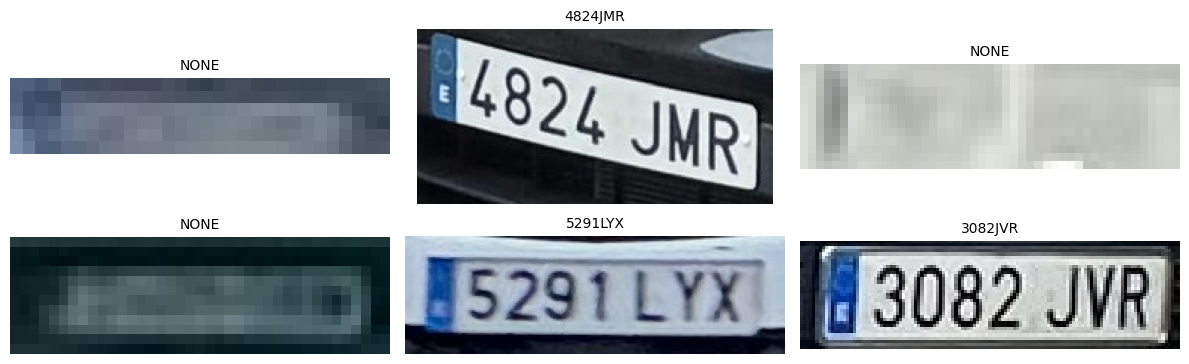

In [12]:
# Elegimos la muestra una sola vez, con semilla fija
random.seed(SEED)
sample = random.sample(sorted(gt), min(N_IMAGES, len(gt)))
print(f"Muestra: {len(sample)} recortes")

# Comprobación visual de los recortes y su texto
fig, axes = plt.subplots(2, 3, figsize=(12, 4))
for ax, crop_name in zip(axes.ravel(), sample[:6]):
    ax.imshow(cv2.cvtColor(cv2.imread(str(CROPS_DIR / crop_name)), cv2.COLOR_BGR2RGB))
    ax.set_title(gt[crop_name], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Mismas imágenes para todos los modelos
eval_crops = sample
print(f"Imágenes usadas en la comparativa: {len(eval_crops)}")

Imágenes usadas en la comparativa: 100


In [14]:
# Ejecución del benchmark: cada modelo guarda su csv y, si ya existe, se salta
def sync_gpu():
    import torch
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def run_model(name):
    out_file = RESULTS_DIR / f"{name}.csv"
    if out_file.exists():
        print(f"{name}: ya medido, se salta")
        return

    print(f"\n=== {name} ===")
    t0 = time.perf_counter()
    model = build_model(name)
    load_time = time.perf_counter() - t0
    print(f"Carga: {load_time:.1f} s  (dispositivo: {model.device})")

    # Calentamiento previo a la medición
    for crop_name in eval_crops[:WARMUP]:
        model.read(str(CROPS_DIR / crop_name))

    rows = []
    for i, crop_name in enumerate(eval_crops):
        path = str(CROPS_DIR / crop_name)
        sync_gpu()
        t_start = time.perf_counter()
        try:
            raw, conf = model.read(path)
        except Exception as e:
            raw, conf = "", None
            print(f"  fallo en {crop_name}: {e}")
        sync_gpu()
        elapsed = time.perf_counter() - t_start

        rows.append({
            "crop": crop_name,
            "ground_truth": gt[crop_name],
            "raw_prediction": raw,
            "prediction": clean_text(raw),
            "confidence": conf,
            "time_s": elapsed,
            "device": model.device,
            "load_time_s": load_time,
        })
        if (i + 1) % 20 == 0:
            print(f"  {i + 1}/{len(eval_crops)}")

    pd.DataFrame(rows).to_csv(out_file, index=False)

    del model
    gc.collect()
    import torch
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


for model_name in MODEL_NAMES:
    try:
        run_model(model_name)
    except Exception as e:
        print(f"{model_name} no se pudo ejecutar: {e}")


=== easyocr ===


Carga: 13.2 s  (dispositivo: cuda)
  20/100
  40/100
  60/100
  80/100
  100/100

=== tesseract ===
Carga: 0.0 s  (dispositivo: cpu)
  20/100
  40/100
  60/100
  80/100
  100/100

=== paddleocr ===


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv6_medium_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart y

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

README.md: 0.00B [00:00, ?B/s]

inference.json: 0.00B [00:00, ?B/s]

... (254 outputs left out)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/4.49G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

Carga: 56.3 s  (dispositivo: cuda)
  20/100
  40/100
  60/100
  80/100
  100/100


In [15]:
# Métricas por modelo
summary = []
for name in MODEL_NAMES:
    f = RESULTS_DIR / f"{name}.csv"
    if not f.exists():
        continue
    df = pd.read_csv(f, dtype={"ground_truth": str, "prediction": str}).fillna({"prediction": ""})

    exact = (df["prediction"] == df["ground_truth"]).mean()
    # CER: distancia de edición entre lo leído y lo real, dividida entre la longitud real
    cer = np.mean([Levenshtein.distance(p, g) / max(len(g), 1)
                   for p, g in zip(df["prediction"], df["ground_truth"])])
    char_acc = max(0.0, 1 - cer)

    summary.append({
        "model": name,
        "device": df["device"].iloc[0],
        "exact_match": exact,
        "CER": cer,
        "char_accuracy": char_acc,
        "empty_pred_rate": (df["prediction"] == "").mean(),
        "mean_time_s": df["time_s"].mean(),
        "median_time_s": df["time_s"].median(),
        "p95_time_s": df["time_s"].quantile(0.95),
        "load_time_s": df["load_time_s"].iloc[0],
        "n_images": len(df),
    })

summary_df = pd.DataFrame(summary).set_index("model")
summary_df.to_csv(DRIVE_OUT / "summary.csv")
summary_df.round(3)

,device,exact_match,CER,char_accuracy,empty_pred_rate,mean_time_s,median_time_s,p95_time_s,load_time_s,n_images
model,,,,,,,,,,
easyocr,cuda,0.18,0.711,0.289,0.51,0.028,0.021,0.065,13.246,100
tesseract,cpu,0.01,0.800,0.200,0.25,0.158,0.136,0.250,0.012,100
paddleocr,cpu,0.35,0.579,0.421,0.38,0.688,0.390,1.681,32.030,100
unlimited_ocr,cuda,0.04,1.687,0.000,0.00,1.863,1.758,2.282,112.650,100
smolvlm,cuda,0.36,0.629,0.371,0.00,0.346,0.333,0.464,56.282,100


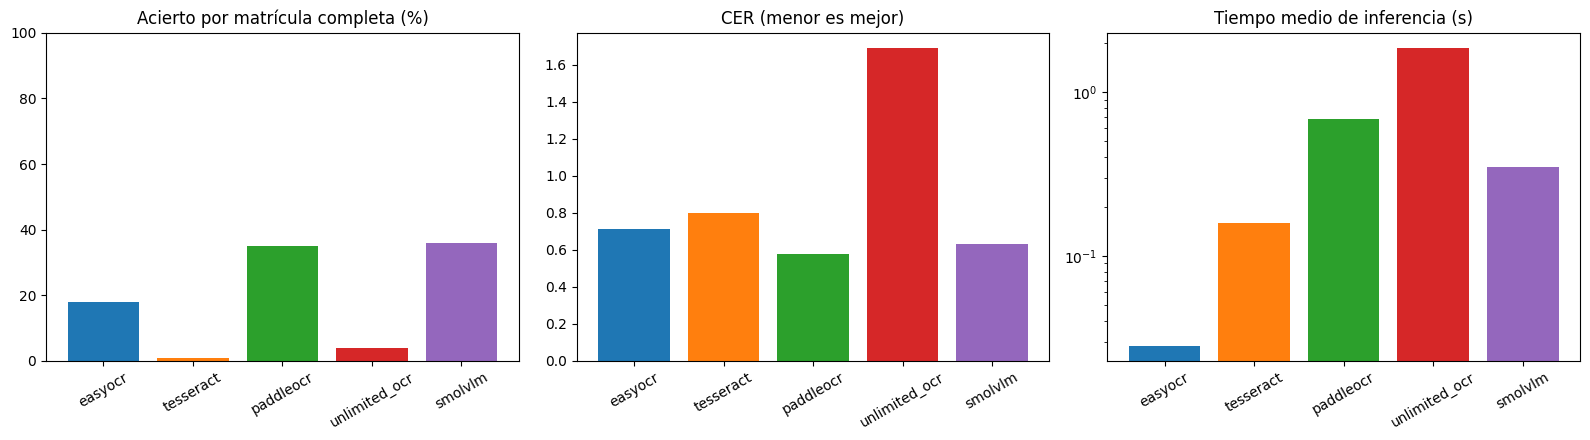

In [16]:
# Gráficas
names = list(summary_df.index)
colors = plt.cm.tab10(np.arange(len(names)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(names, summary_df["exact_match"] * 100, color=colors)
axes[0].set_title("Acierto por matrícula completa (%)")
axes[0].set_ylim(0, 100)

axes[1].bar(names, summary_df["CER"], color=colors)
axes[1].set_title("CER (Character Error Rate)")

axes[2].bar(names, summary_df["mean_time_s"], color=colors)
axes[2].set_title("Tiempo medio de inferencia (s)")
axes[2].set_yscale("log")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "metrics_bars.png", dpi=200)
plt.show()

/tmp/ipykernel_2573/2472154901.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(times, labels=names, showfliers=False)


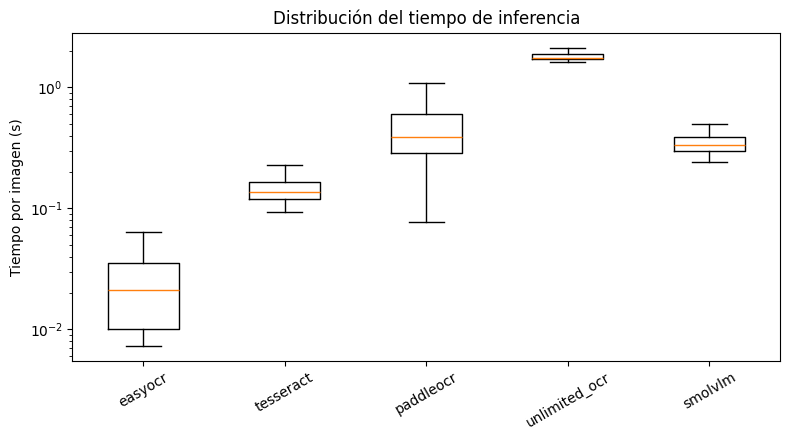

In [17]:
# Distribución de tiempos por imagen
times = [pd.read_csv(RESULTS_DIR / f"{n}.csv")["time_s"].values for n in names]

plt.figure(figsize=(8, 4.5))
plt.boxplot(times, labels=names, showfliers=False)
plt.yscale("log")
plt.ylabel("Tiempo por imagen (s)")
plt.title("Distribución del tiempo de inferencia")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "time_boxplot.png", dpi=200)
plt.show()

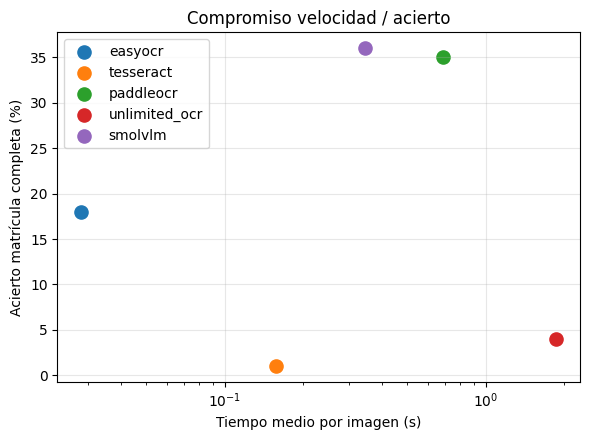

In [18]:
# Acierto frente a tiempo
plt.figure(figsize=(6, 4.5))
for n, c in zip(names, colors):
    plt.scatter(summary_df.loc[n, "mean_time_s"], summary_df.loc[n, "exact_match"] * 100,
                s=90, color=c, label=n)
plt.xscale("log")
plt.xlabel("Tiempo medio por imagen (s)")
plt.ylabel("Acierto matrícula completa (%)")
plt.title("Compromiso velocidad / acierto")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_time.png", dpi=200)
plt.show()

In [19]:
# Ejemplos de predicciones incorrectas
for n in names:
    df = pd.read_csv(RESULTS_DIR / f"{n}.csv", dtype=str).fillna("")
    wrong = df[df["prediction"] != df["ground_truth"]].head(5)
    print(f"\n{n}")
    print(wrong[["crop", "ground_truth", "raw_prediction"]].to_string(index=False))


easyocr
               crop ground_truth raw_prediction
       787-32_4.jpg         NONE               
     IMG_6553_3.jpg         NONE               
IMG_3736_0006_3.jpg         NONE               
      ARQ-111_1.jpg      3082JVR      3082 JVRI
       mgz-39_0.jpg         NONE               

tesseract
                        crop ground_truth raw_prediction
                787-32_4.jpg         NONE               
2026-11-01 at 18.35.09_0.jpg      4824JMR               
              IMG_6553_3.jpg         NONE            UY?
         IMG_3736_0006_3.jpg         NONE              o
              IMG_2553_0.jpg      5291LYX      N5291 LYX

paddleocr
                        crop ground_truth raw_prediction
                787-32_4.jpg         NONE               
2026-11-01 at 18.35.09_0.jpg      4824JMR     4824 JMR E
              IMG_6553_3.jpg         NONE               
         IMG_3736_0006_3.jpg         NONE              1
                mgz-39_0.jpg         NONE             

## Vídeo de test con cada OCR
Genera `video_ocr/salida_<modelo>.mp4` y `video_ocr/tracking_<modelo>.csv` para los cinco modelos. Necesita `C0142.MP4` y `best.pt` en la carpeta VC_P4 de Drive.

In [20]:
%cd /content/drive/MyDrive/VC_P4
!python video_pipeline_ocr.py

/content/drive/MyDrive/VC_P4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

=== Vídeo con easyocr ===
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 201ms
Prepared 1 package in 57ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

{'ocr': 'easyocr', 'frames': 2832, 'vehicles': 44, 'persons': 17, 'plates_read': 8, 'ocr_calls': 152, 'ocr_time_s': 1.63, 'ocr_time_per_call_s': 0.0107, 'total_time_s': 250.59}

=== Vídeo con tesseract ===
{'ocr': 'tesseract', 'frames': 2832, 'vehicles': 44, 'persons': 17, 'plates_read': 19, 'o

In [ ]:
# Métricas sin las matrículas ilegibles (etiqueta NONE en el dataset)
def compute_metrics(name):
    df = pd.read_csv(RESULTS_DIR / f"{name}.csv", dtype={"ground_truth": str, "prediction": str}).fillna({"prediction": ""})
    df = df[df["ground_truth"] != "NONE"]

    cer = np.mean([Levenshtein.distance(p, g) / max(len(g), 1)
                   for p, g in zip(df["prediction"], df["ground_truth"])])
    return {
        "model": name,
        "device": df["device"].iloc[0],
        "exact_match": (df["prediction"] == df["ground_truth"]).mean(),
        "CER": cer,
        "char_accuracy": max(0.0, 1 - cer),
        "empty_pred_rate": (df["prediction"] == "").mean(),
        "mean_time_s": df["time_s"].mean(),
        "median_time_s": df["time_s"].median(),
        "p95_time_s": df["time_s"].quantile(0.95),
        "load_time_s": df["load_time_s"].iloc[0],
        "n_images": len(df),
    }


gt_sample = pd.read_csv(RESULTS_DIR / "easyocr.csv", dtype=str)["ground_truth"]
print(f"Matrículas NONE en la muestra: {(gt_sample == 'NONE').sum()} de {len(gt_sample)}")

summary_legible = pd.DataFrame([compute_metrics(n) for n in MODEL_NAMES if (RESULTS_DIR / f"{n}.csv").exists()]).set_index("model")
summary_legible.to_csv(DRIVE_OUT / "summary_legible.csv")
print(summary_legible.round(3).to_markdown())

names = list(summary_legible.index)
colors = plt.cm.tab10(np.arange(len(names)))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].bar(names, summary_legible["exact_match"] * 100, color=colors)
axes[0].set_title("Acierto por matrícula completa (%) - Sin NONE")
axes[0].set_ylim(0, 100)
axes[1].bar(names, summary_legible["CER"], color=colors)
axes[1].set_title("CER (Character Error Rate) - Sin NONE")
axes[2].bar(names, summary_legible["mean_time_s"], color=colors)
axes[2].set_title("Tiempo medio de inferencia (s)")
axes[2].set_yscale("log")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "metrics_bars_legible.png", dpi=200)
plt.show()

In [ ]:
# Tiempos y compromiso velocidad/acierto sin las matrículas ilegibles
legible_times = []
for n in names:
    df = pd.read_csv(RESULTS_DIR / f"{n}.csv", dtype={"ground_truth": str})
    legible_times.append(df[df["ground_truth"] != "NONE"]["time_s"].values)

plt.figure(figsize=(8, 4.5))
plt.boxplot(legible_times, tick_labels=names, showfliers=False)
plt.yscale("log")
plt.ylabel("Tiempo por imagen (s)")
plt.title("Distribución del tiempo de inferencia - Sin NONE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "time_boxplot_legible.png", dpi=200)
plt.show()

plt.figure(figsize=(6, 4.5))
for n, c in zip(names, colors):
    plt.scatter(summary_legible.loc[n, "mean_time_s"], summary_legible.loc[n, "exact_match"] * 100,
                s=90, color=c, label=n)
plt.xscale("log")
plt.xlabel("Tiempo medio por imagen (s)")
plt.ylabel("Acierto matrícula completa (%)")
plt.title("Compromiso velocidad / acierto - Sin NONE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_time_legible.png", dpi=200)
plt.show()